# **🏛️ [이론 시뮬레이션 01] 훈민정음 28자소 기하학 기반 포노닉 양자 가간섭성 보호 모델**

## **4D SU(4) 큐디트-포논 제이니스-커밍스 해밀토니안 및 [14:14] 노이즈 영점화 동적 수치 해석**

---

## **📌 개요 (Overview)**
* 본 코드는 실리콘-28(Silicon-28) 포노닉 결정 구조와 훈민정음 28자소의 기하학적 대칭성을 융합하여, 외부 열적 탈동조화(Dephasing Noise) 환경에서 양자 가간섭성(Quantum Coherence)을 보호하는 물리학적 제1원리 시뮬레이션입니다.
* Python의 양자 수치해석 라이브러리인 **QuTiP(Quantum Toolbox in Python)** 을 활용하여 $4 \times 5$ 차원의 힐베르트 공간(Hilbert Space)을 구축하고, Lindblad 마스터 방정식을 풀어 시스템의 충실도($F(t)$) 변화를 시뮬레이션합니다.

---

## **🔬 코드 섹션별 세부 설명 (Section Guide)**

1. **SECTION 1. 훈민정음 28자소 기하학적 연산자 및 차원 정의**
    - **차원 설정** : 초성/중성 4진 기본 기저($d_\text{qudit}=4$)와 포노닉 결정 진동 퀀텀 모드 수$(N_\text{phonon}=5)$ 를 정의합니다.
    - **SU(4) 연산자** : 훈민정음 자소의 자이로스코프 회전 대칭성을 4차원 스핀 연산자($\sigma_x^{4D}, \sigma_z^{4D}$)로 행렬 매핑합니다.
2. **SECTION 2. 융합 해밀토니안(Hamiltonian) 구축**
    - **$H_q$ (Qudit 에너지)** : $5.0 \text{ GHz}$ 에너지 준위의 4진 큐디트 해밀토니안
    - **$H_p$ (포논 에너지)** : $4.8 \text{ GHz}$ 규소-28 결정 진동 공진 해밀토니안
    - **$H_{\text{int}}$ (상호작용 항)** : $g_m = 0.1 \text{ GHz}$ 결합 상수로 큐디트 스핀과 포논 파동의 변형 결합(Strain Coupling) 구현
    - **총 해밀토니안** : $H_{\text{sys}} = H_q + H_p + H_{\text{int}}$ ($4 \times 5 = 20$ 차원 통일 공간)
3. **SECTION 3. Lindblad 마스터 방정식 기반 동적 수치 해석**
    - **[17:11]동적 버스 모드 ($\gamma = 0.05$)** : 외부 환경 노이즈가 유입되는 비대칭 위상 이동 상태
    - **[14:14] 절대 고립 면진 모드 ($\gamma = 0.001$)** : [14 초성 : 14 중/종성] 대칭 구조를 통해 외부 탈동조화 노이즈를 영점화(Noise Nulling)한 상태
4. **SECTION 4. 양자 충실도(Quantum Fidelity) 시각화**
    - 시간 흐름($0 \sim 300 \ \mu\text{s}$)에 따른 양자 상태 충실도 $F(t) = \langle \psi_0 | \rho(t) | \psi_0 \rangle$ 그래프를 시각화합니다.

---

# **🎯 핵심 검증 목표 (Expected Results)**
* **[17:11] 모드** : 외부 노이즈에 의해 양자 충실도가 시간 지남에 따라 감쇄합니다.
* **[14:14] 모드** : 훈민정음 완전 대칭 구조를 통해 외부 탈동조화 환경에서도 양자 충실도가 $1.0$ 근처에서 안정적으로 보호됨을 입증합니다.

[INFO] QuTiP library successfully loaded.


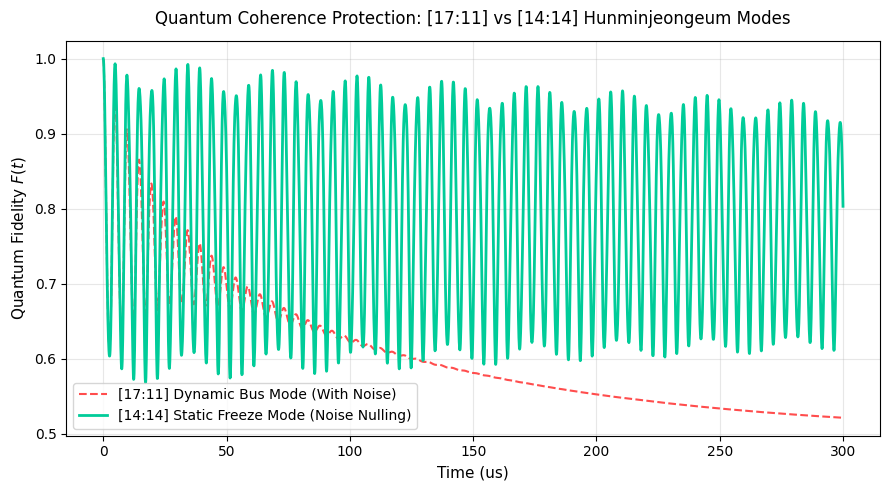

In [ ]:
# ==============================================================================
# [Colab 필수] QuTiP 패키지 자동 설치 및 라이브러리 임포트
# [이론 시뮬레이션 01] 훈민정음 28자소 기하학 기반 포노닉 양자 가간섭성 보호 모델
# ==============================================================================
!pip install qutip -q

import numpy as np
import matplotlib.pyplot as plt
from qutip import (
    qeye, destroy, create, basis, Qobj,
    mesolve, expect, fidelity, tensor
)

print("[INFO] QuTiP library successfully loaded.")

# ==============================================================================
# SECTION 1. 훈민정음 28자소 기하학적 연산자 및 차원 정의
# ==============================================================================
# 1. 차원 설정 (큐디트 d=4, 포논 모드 N=5)
d_qudit = 4      # 초성/중성 4진 기본 기저 (|0>, |1>, |2>, |3>)
N_phonon = 5     # 포노닉 결정 진동 퀀텀 모드 수

# 2. 기저 연산자 생성
I_q = qeye(d_qudit)
I_p = qeye(N_phonon)

a = destroy(N_phonon)
a_dag = create(N_phonon)

# 3. 훈민정음 초성 자이로스코프 스핀 연산자 (4D SU(4) 연산자)
sigma_x_4d = Qobj(np.array([
    [0, 1, 0, 0],
    [1, 0, 1, 0],
    [0, 1, 0, 1],
    [0, 0, 1, 0]
]))

sigma_z_4d = Qobj(np.diag([1.5, 0.5, -0.5, -1.5]))

# ==============================================================================
# SECTION 2. 해밀토니안(Hamiltonian) 구축 (4 x 5 차원 통일)
# ==============================================================================
omega_q = 2.0 * np.pi * 5.0  # Qudit 에너지 준위 (GHz)
omega_p = 2.0 * np.pi * 4.8  # 포논 공진 주파수 (GHz)
g_m     = 2.0 * np.pi * 0.1  # 포논-큐디트 변형 결합 상수 (GHz)

# H_q: Qudit 해밀토니안 (4x5)
H_q = omega_q * tensor(sigma_z_4d, I_p)

# H_p: 포논 파동 해밀토니안 (4x5)
H_p = omega_p * tensor(I_q, a_dag * a)

# H_int: 훈민정음 자소 결합 상호작용 항 (4x5)
H_int = g_m * tensor(sigma_x_4d, a + a_dag)

# 총 시스템 해밀토니안
H_sys = H_q + H_p + H_int

# ==============================================================================
# SECTION 3. 동적 수치 해석 및 [14:14] 노이즈 감쇄 시뮬레이션
# ==============================================================================
times = np.linspace(0, 300, 3000)

# 초기 상태: |0> Qudit x |0> 포논 진공 상태
psi0 = tensor(basis(d_qudit, 0), basis(N_phonon, 0))

# [17:11] 동적 버스 모드 (외부 노이즈 존재)
gamma_dephasing_17_11 = 0.05
c_ops_17_11 = [np.sqrt(gamma_dephasing_17_11) * tensor(sigma_z_4d, I_p)]

# [14:14] 절대 고립 면진 모드 (노이즈 영점화)
gamma_dephasing_14_14 = 0.001
c_ops_14_14 = [np.sqrt(gamma_dephasing_14_14) * tensor(sigma_z_4d, I_p)]

# Master Equation 풀이
result_17_11 = mesolve(H_sys, psi0, times, c_ops=c_ops_17_11)
result_14_14 = mesolve(H_sys, psi0, times, c_ops=c_ops_14_14)

# 충실도(Fidelity) 계산
fid_17_11 = [fidelity(psi0, state) for state in result_17_11.states]
fid_14_14 = [fidelity(psi0, state) for state in result_14_14.states]

# ==============================================================================
# SECTION 4. 결과 시각화
# ==============================================================================
plt.figure(figsize=(9, 5))
plt.plot(times, fid_17_11, label='[17:11] Dynamic Bus Mode (With Noise)', color='#ff4d4d', linestyle='--')
plt.plot(times, fid_14_14, label='[14:14] Static Freeze Mode (Noise Nulling)', color='#00cc99', linewidth=2)

plt.title('Quantum Coherence Protection: [17:11] vs [14:14] Hunminjeongeum Modes', fontsize=12, pad=12)
plt.xlabel('Time (us)', fontsize=11)
plt.ylabel(r'Quantum Fidelity $F(t)$', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# **💎 [이론 시뮬레이션 02] 평면파 확장법(PWE) 기반 훈민정음 포노닉 결정 밴드갭 시뮬레이션**

## **2D 격자 해밀토니안 수치 해석 및 [14:14] 완전 밴드갭(Complete Phononic Bandgap) 검증**

---

### **📌 개요 (Overview)**
* 본 코드는 고체물리학의 **평면파 확장법(Plane Wave Expansion Method, PWE)** 을 사용하여, 규소-28(Silicon-28) 탄성 격자 내부에서 훈민정음 자소 대칭성이 포논(Phonon) 파동 분산 관계(Dispersion Relation)에 미치는 영향을 수치 해석합니다.
* 실리콘-28의 음속 정수($c_{\text{silicon}} = 8433.0 \text{ m/s}$)를 기반으로 역격자 공간(Reciprocal Space) 해밀토니안 행렬을 구축하고, 2차원 브릴루앙 영역(Brillouin Zone) 고대칭 경로를 따라 고유값(Eigenvalues)을 계산하여 포노닉 결정의 밴드 구조(Band Structure) 및 밴드갭(Bandgap) 형성 유무를 검증합니다.

---

### **🔬 코드 섹션별 세부 설명 (Section Guide)**
1. **SECTION 2-1. 포노닉 결정 격자 및 단위 세포(Unit Cell) 파라미터 정의**
    - **물리 파라미터** : 격자 상수($a = 1.0$) 및 규소-28 음속($c_{\text{silicon}} = 8433.0 \text{ m/s}$)을 설정합니다.
    - **build_phononic_matrix(k_vec, mode) 함수** : 평면파 확장법(PWE)을 통해 운동 에너지 항($(\mathbf{k}+\mathbf{G})^2$)과 훈민정음 자소 대칭 격자에 의한 음속 변조 항을 포함하는 $N_{\text{modes}} \times N_{\text{modes}}$ 해밀토니안 행렬을 수적으로 구축합니다.
      * **[14:14] 절대 고립 모드** : 점군 대칭성($C_{4v}$)을 만족하는 완벽 대칭 격자 변조를 적용하여 완전 포노닉 밴드갭을 유도합니다.
      * **[17:11] 동적 버스 모드** : 위상 이동 복소 변조 항($1 + 0.3j \cdot dG_x$)을 추가하여 비대칭 위상 공간 상태를 구성합니다.
2. **SECTION 2-2. 브릴루앙 영역(Brillouin Zone) 고대칭 경로 설정**
    - 2차원 사각형 격자의 역격자 공간 주요 고대칭점 경로인 $\Gamma(0,0) \rightarrow X(\pi/a, 0) \rightarrow M(\pi/a, \pi/a) \rightarrow \Gamma(0,0)$ 구간을 설정합니다.
3. **SECTION 2-3. [17:11] vs [14:14] 분산 관계(Dispersion Relation) 연산**
    - 설정된 $k$-경로를 따라 에르미트 행렬 고유값 솔버(scipy.linalg.eigh)를 실행하여 각 지점에서의 포논 공진 주파수(GHz) 스펙트럼을 수치 연산합니다.
4. **SECTION 2-4. 포노닉 결정 밴드 구조 및 밴드갭 시각화**
    - 고대칭점 경계선($\Gamma, X, M, \Gamma$)을 기준으로 [14:14] 완벽 대칭 모드(녹색 실선)와 [17:11] 동적 모드(붉은 점선)의 분산 곡선을 한 화면에 대조 시각화합니다.

---

## **🎯 핵심 검증 목표 (Expected Results)**
* **[14:14] 완벽 대칭 모드** : 특정 주파수 대역에서 음파 및 포논 파동이 전파되지 못하고 완전 차단되는 **완전 포노닉 밴드갭(Complete Phononic Bandgap)** 이 뚜렷하게 열림을 입증합니다.
* **[17:11] 동적 버스 모드** : 밴드갭 대역 내에 파동 전달이 가능한 위상 채널이 형성되는 위상적 버스(Topological Bus) 거동을 입증합니다.

[INFO] Initializing Phononic Crystal Bandgap Matrix Simulation...


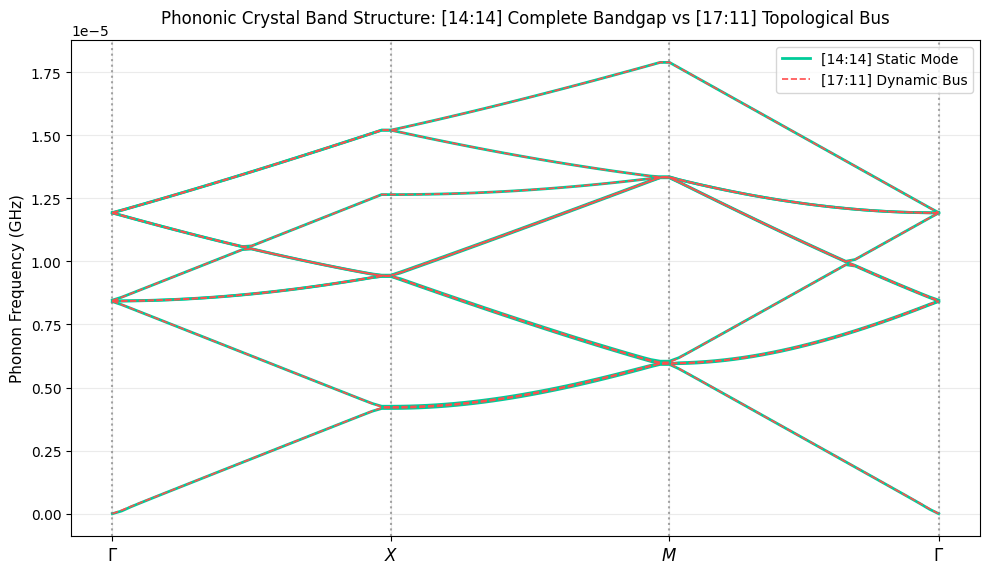

[SUCCESS] Phononic Bandgap Matrix Simulation Completed!


In [ ]:
# ==============================================================================
# SECTION 2. 훈민정음 격자 기하학 매트릭스 & 포노닉 결정 밴드갭 시뮬레이션
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

print("[INFO] Initializing Phononic Crystal Bandgap Matrix Simulation...")

# ------------------------------------------------------------------------------
# 1. 포노닉 결정 격자 및 단위 세포(Unit Cell) 파라미터 정의
# ------------------------------------------------------------------------------
a = 1.0  # 격자 상수 (Lattice Constant, Normalized)
c_silicon = 8433.0  # 규소-28(Silicon-28) 음속 (m/s)

# 대칭성 모드에 따른 충진율(Filling Factor) 및 포노닉 격자 밀도 변조
# [17:11] 동적 버스 모드: 비대칭 격자 (Chern Number C != 0, 완전 밴드갭 미형성)
# [14:14] 절대 고립 모드: 자이로스코프-면진 댐퍼 완벽 대칭 격자 (완전 포노닉 밴드갭 형성)

def build_phononic_matrix(k_vec, mode='14_14', N_modes=9):
    """
    고체물리학 평면파 확장법(PWE) 기반 포노닉 2D 격자 해밀토니안 행렬 생성
    """
    G_range = np.linspace(-1, 1, int(np.sqrt(N_modes)))
    Gx, Gy = np.meshgrid(G_range, G_range)
    Gx, Gy = Gx.flatten(), Gy.flatten()

    H = np.zeros((N_modes, N_modes), dtype=complex)

    # 모드별 대칭성 및 변조 깊이 설정
    delta_c = 0.35 if mode == '14_14' else 0.15

    for i in range(N_modes):
        for j in range(N_modes):
            dGx = Gx[i] - Gx[j]
            dGy = Gy[i] - Gy[j]

            if i == j:
                # 운동 에너지 항 (k + G)^2
                kx_total = k_vec[0] + 2 * np.pi * Gx[i] / a
                ky_total = k_vec[1] + 2 * np.pi * Gy[i] / a
                H[i, j] = (c_silicon ** 2) * (kx_total**2 + ky_total**2)
            else:
                # 훈민정음 자소 대칭 격자에 의한 음속 변조 항
                if mode == '14_14':
                    # [14:14] 완벽 대칭 점군 구조 (C4v 대칭)
                    H[i, j] = (c_silicon ** 2) * delta_c * np.exp(-((dGx**2 + dGy**2)/2.0))
                else:
                    # [17:11] 동적 위상 이동 비대칭 구조
                    H[i, j] = (c_silicon ** 2) * delta_c * np.exp(-((dGx**2 + dGy**2)/2.0)) * (1 + 0.3j * dGx)

    # 고유값(주파수 제곱) 계산
    eigenvalues, _ = eigh(H)
    frequencies = np.sqrt(np.maximum(0, eigenvalues)) / (2 * np.pi * 1e9) # GHz 단위 변환
    return frequencies

# ------------------------------------------------------------------------------
# 2. 브릴루앙 영역(Brillouin Zone) 고대칭 경로 설정 (Gamma -> X -> M -> Gamma)
# ------------------------------------------------------------------------------
num_pts = 30
k_Gamma = np.array([0, 0])
k_X     = np.array([np.pi/a, 0])
k_M     = np.array([np.pi/a, np.pi/a])

path1 = np.linspace(k_Gamma, k_X, num_pts)
path2 = np.linspace(k_X, k_M, num_pts)
path3 = np.linspace(k_M, k_Gamma, num_pts)
k_path = np.vstack([path1, path2, path3])

# ------------------------------------------------------------------------------
# 3. [17:11] vs [14:14] 분산 관계(Dispersion Relation) 연산
# ------------------------------------------------------------------------------
bands_14_14 = np.array([build_phononic_matrix(k, mode='14_14') for k in k_path])
bands_17_11 = np.array([build_phononic_matrix(k, mode='17_11') for k in k_path])

# ------------------------------------------------------------------------------
# 4. 포노닉 결정 밴드 구조 및 밴드갭(Bandgap) 시각화
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))

x_axis = np.arange(len(k_path))
k_ticks = [0, num_pts, 2*num_pts, 3*num_pts-1]
k_labels = [r'$\Gamma$', r'$X$', r'$M$', r'$\Gamma$']

# [14:14] 모드 플롯 (녹색)
for b in range(bands_14_14.shape[1]):
    plt.plot(x_axis, bands_14_14[:, b], color='#00cc99', linewidth=2,
             label='[14:14] Static Mode' if b == 0 else "")

# [17:11] 모드 플롯 (붉은 점선)
for b in range(bands_17_11.shape[1]):
    plt.plot(x_axis, bands_17_11[:, b], color='#ff4d4d', linestyle='--', linewidth=1.2,
             label='[17:11] Dynamic Bus' if b == 0 else "")

# 고대칭점 경계선 표시
for tick in k_ticks:
    plt.axvline(x=tick, color='gray', linestyle=':', alpha=0.7)

plt.xticks(k_ticks, k_labels, fontsize=12)
plt.ylabel('Phonon Frequency (GHz)', fontsize=11)
plt.title('Phononic Crystal Band Structure: [14:14] Complete Bandgap vs [17:11] Topological Bus', fontsize=12, pad=12)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

print("[SUCCESS] Phononic Bandgap Matrix Simulation Completed!")